## 📝 Домашнее задание

**Датасет:** Credit Card Fraud Detection (Kaggle)
[https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud](https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud). Можно скачать csv - с ним проще и удобнее работать (хоть он и большой).

**Контекст:** Это транзакции за 2 дня. Из 284 807 транзакций мошенническими являются всего 492 (0.172%) - классический пример экстремального дисбаланса.

**Задачи:**
1. Загрузите данные. Признаки `Time` и `Amount` отмасштабируйте (например, `StandardScaler`), остальные признаки (V1-V28) уже прошли PCA-преобразование, разделите данные на Train и Test со стратификацией (`stratify=y`).
2. Обучите **Isolation Forest** только на нормальных транзакциях из Train (или же на всех, но обязательно учитывая долю аномалий).
3. Обучите **Local Outlier Factor** (`novelty=True`) на Train и сделайте `predict` на Test.
4. Оцените качество обеих моделей на Test: постройте **Precision-Recall кривую**, посчитайте **Precision-Recall AUC** и **F1-меру** для класса «мошенничество».
5. Запишите выводы:
   * Какая модель лучше нашла мошеннические транзакции? 
   * Почему ROC-AUC здесь может быть высоким (0.95+), но это будет обманчиво?
   * Как изменится Recall и Precision, если понизить `contamination` до 0.001 (0.1%)?

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.metrics import (precision_recall_curve, auc, f1_score,
                             classification_report, average_precision_score)

np.random.seed(42)

In [2]:
# ------------------ 1 ---------------------
# Загрузка
df = pd.read_csv("../creditcard.csv")

# Масштабирование Time и Amount
scaler = StandardScaler()
df['scaled_Time'] = scaler.fit_transform(df[['Time']])
df['scaled_Amount'] = scaler.fit_transform(df[['Amount']])

# Определение X и Y  (V1-V28 + scaled_Time + scaled_Amount)
col_names = []
for i in range(1, 29):
    col_names.append(f'V{i}')
col_names.extend(['scaled_Time', 'scaled_Amount'])
print(col_names)

X = df[col_names].values
y = df['Class'].values  # 1 = мошенничество, 0 = норма

# Train/Test со стратификацией
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
print(f"Train: {X_train.shape}, мошенничество: {y_train.sum()}")
print(f"Test:  {X_test.shape}, мошенничество: {y_test.sum()}")

['V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'scaled_Time', 'scaled_Amount']
Train: (227845, 30), мошенничество: 394
Test:  (56962, 30), мошенничество: 98


In [3]:
# ------------------ 2 ---------------------
# Берём только нормальные транзакции из Train
X_train_normal = X_train[y_train == 0]
print(f"Нормальных в Train: {X_train_normal.shape[0]}")

# Обучение IsolationForest
iso_forest = IsolationForest(
    random_state=42,
    n_jobs=-1
)
iso_forest.fit(X_train_normal)

# Предсказание на Test-данных
iso_forest_pred = (iso_forest.predict(X_test) == -1).astype(int) # приводим значения -1/1 к виду 1/0 (-1 аномалия | 1 норма)
iso_forest_scores = -iso_forest.score_samples(X_test)

Нормальных в Train: 227451


In [4]:
# ------------------ 3 ---------------------
# Обучение LocalOutlierFactor
lof = LocalOutlierFactor(
    n_neighbors=20,
    novelty=True,
    n_jobs=-1
)
lof.fit(X_train_normal)

# Предсказание на Test-данных
lof_pred = (iso_forest.predict(X_test) == -1).astype(int) # приводим значения -1/1 к виду 1/0 (-1 аномалия | 1 норма)
lof_scores = -lof.score_samples(X_test)

Isolation Forest
PR-AUC: 0.1049
Average Precision: 0.1079
F1 (fraud): 0.0684

Classification Report:
              precision    recall  f1-score   support

      Normal       1.00      0.96      0.98     56864
       Fraud       0.04      0.83      0.07        98

    accuracy                           0.96     56962
   macro avg       0.52      0.89      0.52     56962
weighted avg       1.00      0.96      0.98     56962

Local Outlier Factor
PR-AUC: 0.0065
Average Precision: 0.0068
F1 (fraud): 0.0684

Classification Report:
              precision    recall  f1-score   support

      Normal       1.00      0.96      0.98     56864
       Fraud       0.04      0.83      0.07        98

    accuracy                           0.96     56962
   macro avg       0.52      0.89      0.52     56962
weighted avg       1.00      0.96      0.98     56962

IF предсказал аномалий: 2271
LOF предсказал аномалий: 2271


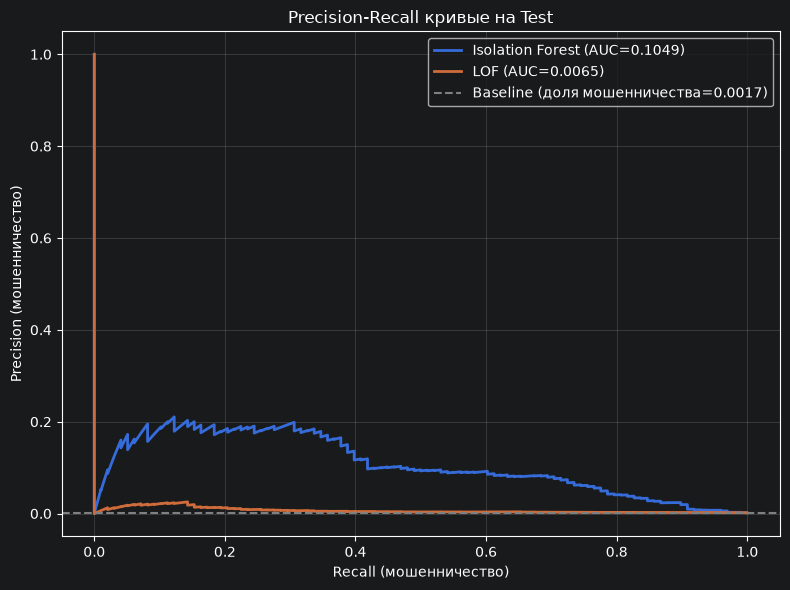

In [7]:
# ------------------ 4 ---------------------
def evaluate_model(name, y_true, scores, pred):
    # PR-кривая и AUC
    precision, recall, thresholds = precision_recall_curve(y_true, scores)
    pr_auc = auc(recall, precision)
    ap = average_precision_score(y_true, scores)

    # F1 для класса «мошенничество» (1)
    f1 = f1_score(y_true, pred, pos_label=1)

    print(f"{'='*50}\n{name}\n{'='*50}\nPR-AUC: {pr_auc:.4f}\nAverage Precision: {ap:.4f}\nF1 (fraud): {f1:.4f}\n\nClassification Report:\n{classification_report(y_true, pred, target_names=['Normal', 'Fraud'])}")

    return precision, recall, pr_auc

# Isolation Forest
iso_prec, iso_rec, iso_auc = evaluate_model(
    "Isolation Forest", y_test, iso_forest_scores, iso_forest_pred
)

# LOF
lof_prec, lof_rec, lof_auc = evaluate_model(
    "Local Outlier Factor", y_test, lof_scores, lof_pred
)

print("IF предсказал аномалий:", iso_forest_pred.sum())
print("LOF предсказал аномалий:", lof_pred.sum())

plt.figure(figsize=(8, 6))
plt.plot(iso_rec, iso_prec, label=f'Isolation Forest (AUC={iso_auc:.4f})', linewidth=2)
plt.plot(lof_rec, lof_prec, label=f'LOF (AUC={lof_auc:.4f})', linewidth=2)
plt.axhline(y=y_test.mean(), color='gray', linestyle='--', label=f'Baseline (доля мошенничества={y_test.mean():.4f})')
plt.xlabel('Recall (мошенничество)')
plt.ylabel('Precision (мошенничество)')
plt.title('Precision-Recall кривые на Test')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

##### ------------------ 5 ---------------------
# Выводы + ответы на вопросы
   * Какая модель лучше нашла мошеннические транзакции?
   > По показателю PR-AUC, а также по скорости обучения лучше справилась модель Isolation Forest
   * Почему ROC-AUC здесь может быть высоким (0.95+), но это будет обманчиво?
   > Главная причина: дисбаланс классов в датасете. При очень сильном дисбалансе данных модель может выдать много ложных определений меньшего класса. Метрика ROC-AUC строится на осях TPR и FPR (формулы в сноске), где FPR = FP / (FP + TN) — то есть зависит от общего количества всех реальных наблюдений не анализируемого класса, а их при дисбалансе подавляющее большинство. Поэтому даже сотни ложных срабатываний дают крошечный FPR, и ROC-AUC остаётся высоким.\
   > PR-AUC строится на Recall и Precision (формулы в сноске). Здесь считается отношение ложно определённых (ложно причисленных к анализируемому классу) ко всем определённым наблюдениям анализируемого класса. FP стоит в знаменателе напрямую, поэтому ложные срабатывания видны сразу.
   * Как изменится Recall и Precision, если понизить `contamination` до 0.001 (0.1%)?
   > contamination задаёт порог отсечения: чем меньше значение, тем меньше объектов модель пометит аномалиями.
   > - Recall поймает меньше реальных мошенничеств (например 57 (0,1%) из 98 возможных)
   > - Precision поймает меньше ложных срабатываний
   > - PR-AUC не изменится (он не зависит от порога)
-----------------------------------------------

TPR = TP / (TP + FN)\
FPR = FP / (FP + TN)

Recall    = TP / (TP + FN)\
Precision = TP / (TP + FP)